<p><a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a></p>

<p><a href="https://query.farm/vgi/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/vgi-logo.png" alt="VGI" width="112"></a></p>

# [XSLT and XQuery](https://github.com/Query-farm/vgi-xslt)

Transform and query XML documents from SQL with XSLT, XQuery and XPath.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Query-farm/vgi-xslt/blob/main/notebooks/02_same_units_different_row_counts.ipynb)

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Example notes](https://github.com/Query-farm/vgi-xslt/blob/main/notebooks/README.md)

## 02 · The same unit total can describe different rows

A zero-quantity order line contributes no units, but it is still a row. Can a scalar
XML summary tell us whether it was retained? We will compare XPath's row function,
XQuery's row function and a scalar XQuery summary on one small authored order.

Duplicate SKUs remain separate source lines. We carry each line's ID through the
selection so a newly numbered result cannot masquerade as a stable source identity.
The experiment removes zero quantities: the row count should change while units stay fixed.

### Choose whether a known zero belongs in the selected view

Keep `INCLUDE_ZERO = True` for the default. The experiment sets it to `False`.
Both views exclude an absent quantity; neither imputes it as zero. These are
synthetic local records, not a network service or a received production order.

In [1]:
INCLUDE_ZERO = True

In [2]:
import importlib.metadata as packages
import sys

installed = {d.metadata["Name"]: d.version for d in packages.distributions()}
if installed.get("vgi-example-notebooks") != "0.3.19":
    %pip install -q "git+https://github.com/Query-farm/vgi-example-notebooks@v0.3.19"
    if "vgi_notebooks" in sys.modules:
        raise RuntimeError("Restart the session after updating the example tools, then run all.")

In [3]:
import pandas as pd
from IPython.display import display
from vgi_notebooks import check_runtime, connect, prepare, prose, theme

check_runtime()
prepare("xslt")
import xslt_example as example  # noqa: E402 — download before import

if type(INCLUDE_ZERO) is not bool:
    raise ValueError("INCLUDE_ZERO must be True or False.")
source_audit = summary = totals = checks = pd.DataFrame()
theme()
session = connect(globals())
con = session.connection

### Connect to the released XML engine

This literal ATTACH runs **v0.4.0** in a separate environment. First setup downloads
SaxonC-HE's native wheel; no checkout or dependency overrides are needed. The
capabilities row makes the lack of XSD validation explicit. We supply all XML and
queries locally.

In [4]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'xslt' (TYPE vgi,
 LOCATION 'uvx --python 3.13 --from git+https://github.com/Query-farm/vgi-xslt@v0.4.0 vgi-xslt-worker');
SELECT * FROM xslt.main.saxon_info;

,version,edition,xslt_version,xquery_version,xpath_version,schema_aware
0,SaxonC-HE 13.1 from Saxonica,Home Edition (HE),3.0,3.1,3.1,False


### Keep the five source lines visible

Lines `L1` and `L2` both describe apples; `L3` and `L4` both describe pears.
`L2` has an explicit zero, while `L5` has no quantity. A SKU is a category, not a
unique line identifier. The full source audit is unchanged by the selection switch.

In [5]:
%%sql source_audit <<
CREATE TABLE source_document AS SELECT $xml$
<order id="O-1">
 <item line="L1" sku="apple" qty="2"/>
 <item line="L2" sku="apple" qty="0"/>
 <item line="L3" sku="pear" qty="5"/>
 <item line="L4" sku="pear" qty="3"/>
 <item line="L5" sku="peach"/>
</order>
$xml$ AS xml;
CREATE TABLE source_items AS
SELECT t.ordinality AS source_position,
 xslt.main.xpath_string(t.value, '/item/@line') AS line_id,
 xslt.main.xpath_string(t.value, '/item/@sku') AS sku,
 try_cast(xslt.main.xpath_string(t.value, '/item/@qty') AS BIGINT) AS quantity
FROM source_document d,
 UNNEST(xslt.main.xpath_array(d.xml, '/order/item ! serialize(.)'))
 WITH ORDINALITY AS t(value, ordinality);
SELECT * FROM source_items ORDER BY source_position;

In [6]:
display(source_audit)
assert len(source_audit) == 5 and source_audit.line_id.is_unique
assert source_audit.quantity.isna().sum() == 1
prose("Five source lines include four known nonnegative quantities and one missing quantity. "
      "The known total is ten units; it does not estimate the missing line's quantity.")

,source_position,line_id,sku,quantity
0,1,L1,apple,2
1,2,L2,apple,0
2,3,L3,pear,5
3,4,L4,pear,3
4,5,L5,peach,<NA>


Five source lines include four known nonnegative quantities and one missing quantity. The known total is ten units; it does not estimate the missing line's quantity.

### Apply one predicate in both row-returning forms

Both expressions select nonnegative integer quantities, then optionally exclude
zero. They explicitly **serialize** each selected element: selecting an empty
`item` element's string value alone would lose its attributes.

`xpath_nodes` emits one row per XPath match. `xquery_rows` emits one row per item in
an XQuery result sequence. Their `seq` columns number the selected result; the
carried `line` attribute is the stable source identity. We quote the single authored
XML value and expressions as SQL literals so the table-function arguments stay constant.

In [7]:
document_sql = example.sql_text(con.execute("SELECT xml FROM source_document").fetchone()[0])
node_path = "/order/item[@qty castable as xs:integer][xs:integer(@qty) >= 0]"
if not INCLUDE_ZERO:
    node_path += "[xs:integer(@qty) > 0]"
xpath_expression = node_path + " ! serialize(.)"
row_query = f"for $item in {node_path} return serialize($item)"
summary_query = (f"let $items := {node_path} return "
                 "<summary rows='{count($items)}' units='{sum($items/@qty ! xs:integer(.))}'/>")

In [8]:
%%sql
CREATE TABLE xpath_selected AS
SELECT seq AS result_position,
 xslt.main.xpath_string(value, '/item/@line') AS line_id,
 xslt.main.xpath_string(value, '/item/@sku') AS sku,
 xslt.main.xpath_number(value, 'xs:integer(/item/@qty)')::BIGINT AS quantity
FROM xslt.main.xpath_nodes({{ document_sql }}, {{ example.sql_text(xpath_expression) }});
CREATE TABLE xquery_selected AS
SELECT seq AS result_position,
 xslt.main.xpath_string(value, '/item/@line') AS line_id,
 xslt.main.xpath_string(value, '/item/@sku') AS sku,
 xslt.main.xpath_number(value, 'xs:integer(/item/@qty)')::BIGINT AS quantity
FROM xslt.main.xquery_rows({{ document_sql }}, {{ example.sql_text(row_query) }});
SELECT s.source_position, x.result_position, x.line_id, x.sku, x.quantity
FROM xquery_selected x JOIN source_items s USING(line_id)
ORDER BY x.result_position;

,source_position,result_position,line_id,sku,quantity
0,1,1,L1,apple,2
1,2,2,L2,apple,0
2,3,3,L3,pear,5
3,4,4,L4,pear,3


### Reconcile the scalar summary with the selected rows

A scalar XQuery returns one serialized summary. It is useful for a compact aggregate,
but its total cannot explain which source lines were selected. We extract its count
and units, compare them to the row relation, and retain the full source denominator.

In [9]:
%%sql summary <<
CREATE TABLE scalar_summary AS
SELECT xslt.main.xquery({{ document_sql }}, {{ example.sql_text(summary_query) }}) AS xml;
SELECT xml,
 xslt.main.xpath_number(xml, 'xs:integer(/summary/@rows)')::BIGINT AS selected_rows,
 xslt.main.xpath_number(xml, 'xs:integer(/summary/@units)')::BIGINT AS known_units,
 (SELECT count(*) FROM source_items) AS source_lines,
 (SELECT count(*) FROM source_items WHERE quantity IS NULL) AS missing_quantities
FROM scalar_summary;

In [10]:
display(summary)
prose(f"The scalar reports **{int(summary.selected_rows.iloc[0])} selected lines** and "
      f"**{int(summary.known_units.iloc[0])} known units**. The source still has "
      f"**{int(summary.source_lines.iloc[0])} lines**, including "
      f"**{int(summary.missing_quantities.iloc[0])} missing quantity**. "
      "Read the line IDs above to determine whether the explicit zero survived.")

,xml,selected_rows,known_units,source_lines,missing_quantities
0,"<summary rows=""4"" units=""10""/>",4,10,5,1


The scalar reports **4 selected lines** and **10 known units**. The source still has **5 lines**, including **1 missing quantity**. Read the line IDs above to determine whether the explicit zero survived.

In [11]:
%%sql totals <<
SELECT sku, count(*) AS selected_lines, sum(quantity) AS known_units
FROM xquery_selected GROUP BY sku ORDER BY sku;

### Row counts and unit counts answer different questions

Each panel has its own labeled unit and scale. Aggregating by SKU is intentional
for this report, after preserving line identity in the audit. The missing peach
quantity is outside this selected known-quantity view, not silently converted to zero.

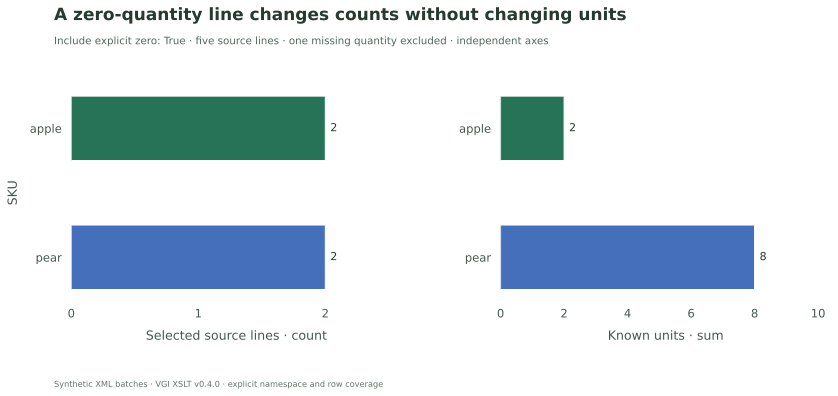

In [12]:
example.plot_rows_and_units(totals, INCLUDE_ZERO)

### Compare row meaning, not serialized whitespace

Bidirectional differences compare typed line IDs, quantities, SKUs and result
positions. The checks also reconcile source selection and the scalar aggregate.
They do not assert that alternative serializers produce byte-identical XML.

In [13]:
%%sql checks <<
SELECT 'Both row functions return the same typed rows' AS check_name,
 NOT EXISTS(SELECT * FROM xpath_selected EXCEPT SELECT * FROM xquery_selected)
 AND NOT EXISTS(SELECT * FROM xquery_selected EXCEPT SELECT * FROM xpath_selected) AS passed
UNION ALL SELECT 'Source line identities survive selection',
 NOT EXISTS(SELECT line_id,sku,quantity FROM xquery_selected EXCEPT
   SELECT line_id,sku,quantity FROM source_items WHERE quantity>=0 AND ({{ INCLUDE_ZERO }} OR quantity>0))
 AND NOT EXISTS(SELECT line_id,sku,quantity FROM source_items WHERE quantity>=0 AND ({{ INCLUDE_ZERO }} OR quantity>0)
   EXCEPT SELECT line_id,sku,quantity FROM xquery_selected)
UNION ALL SELECT 'Selected identities remain unique',
 (SELECT count(*)=count(DISTINCT line_id) FROM xquery_selected)
UNION ALL SELECT 'Missing quantity stays unknown and outside selection',
 (SELECT quantity IS NULL FROM source_items WHERE line_id='L5')
 AND NOT EXISTS(SELECT 1 FROM xquery_selected WHERE line_id='L5')
UNION ALL SELECT 'Zero follows the selected policy',
 (SELECT count(*) FROM xquery_selected WHERE line_id='L2') = CASE WHEN {{ INCLUDE_ZERO }} THEN 1 ELSE 0 END
UNION ALL SELECT 'Known unit total is independent of excluding zero',
 (SELECT sum(quantity)=10 FROM xquery_selected)
UNION ALL SELECT 'Both duplicate pear lines remain distinct',
 (SELECT count(*)=2 AND sum(quantity)=8 FROM xquery_selected WHERE sku='pear');

In [14]:
assert checks.passed.all(), checks.loc[~checks.passed].to_dict("records")
assert int(totals.selected_lines.sum()) == int(summary.selected_rows.iloc[0])
assert int(totals.known_units.sum()) == int(summary.known_units.iloc[0])
assert int(summary.selected_rows.iloc[0]) == (4 if INCLUDE_ZERO else 3)
display(checks)
prose(f"**{len(checks)} SQL checks and three aggregate reconciliations passed.** "
      "Matching unit totals alone would not have established matching selected rows.")

,check_name,passed
0,Both row functions return the same typed rows,True
1,Source line identities survive selection,True
2,Selected identities remain unique,True
3,Missing quantity stays unknown and outside sel...,True
4,Zero follows the selected policy,True
5,Known unit total is independent of excluding zero,True
6,Both duplicate pear lines remain distinct,True


**7 SQL checks and three aggregate reconciliations passed.** Matching unit totals alone would not have established matching selected rows.

### Experiment · exclude the explicit zero

Set only `INCLUDE_ZERO = False`, restart and run all. Predict that `L2` disappears,
`L3` and `L4` receive new result positions, and the source IDs remain unchanged.
The selected row count should fall from four to three while the known total stays
ten. The one missing quantity remains unknown in both runs.

Compare the full source table, source/result positions, scalar summary and both
chart panels. Restore `True` for the default.

```sh
uv run --locked vgi-notebooks 02_same_units_different_row_counts.ipynb \
  --parameters '{"INCLUDE_ZERO":false}' --output-dir artifacts/exclude-zero
```

[The first notebook](01_preserve_documents_when_shredding_xml.ipynb) adds multiple
documents, namespace isolation, malformed input and XSLT normalization.

In [15]:
session.close()

<a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Worker repository: vgi-xslt](https://github.com/Query-farm/vgi-xslt)